# Separating the microwave sky by its spectrum

## 1. The imaging question

The same sky direction emits through multiple physical processes. Cosmic microwave background temperature fluctuations overlap synchrotron radiation from relativistic electrons and thermal emission from interstellar dust. Five microwave images therefore contain several spatially mixed fields. We recover three conditional component maps from real WMAP nine-year observations, with each foreground spectrum explicitly fixed. We do not infer new spectral-index fields or call the recovered components physical ground truth.

The maps are differential thermodynamic microkelvin. A change in frequency alters foreground amplitude but leaves the calibrated cosmic microwave background response constant. This spectral distinction supplies the information for the inverse.

In [1]:
from pathlib import Path
import sys,time,json,os,platform
import numpy as np
import matplotlib,matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src import visualization as viz
print('ACTUAL_KERNEL_ENVIRONMENT',json.dumps({'executable':sys.executable,'python':sys.version,'os':platform.platform(),'numpy':np.__version__,'numpy_file':np.__file__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}))
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:
    author=np.stack([f[k][0] for k in ['reconstruction','synchrotron','dust']])
sources={}
def show(name,result):
    fig,numeric=result
    sources.update({name+'_'+k:v for k,v in numeric.items()})
    plt.show()
print('Observed shapes:',{k:v.shape for k,v in data.items()})

ACTUAL_KERNEL_ENVIRONMENT {"executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe", "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]", "os": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "numpy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\numpy\\__init__.py", "matplotlib": "3.11.1", "backend": "module://matplotlib_inline.backend_inline", "threads": {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}}
Observed shapes: {'measurements': (5, 48, 64), 'galactic_longitude': (48, 64), 'galactic_latitude': (48, 64), 'frequencies': (5,)}


## 2. What was observed

The bound patch covers Galactic longitude70–102degrees and latitude12–36degrees, with48latitude and64longitude positions. Each band supplies the native HEALPix pixel containing that direction. No flat-map interpolation or additional beam convolution is performed. All five source products were already smoothed to1degree angular FWHM; neighboring sky samples are consequently correlated. Observations are float32mK values promoted exactly to float64 and multiplied by1000to express microkelvin.

The effective-frequency approximation uses22.8,33.0,40.7,60.8,93.5GHz. It does not model full instrument bandpasses. No foreground-reduced WMAP map or target-derived foreground template enters the data. The fixed spectral assumptions are part of this conditional benchmark, not newly measured calibration. The source publication supports the mathematical method; these are new independent method measurements on the bound real observations.

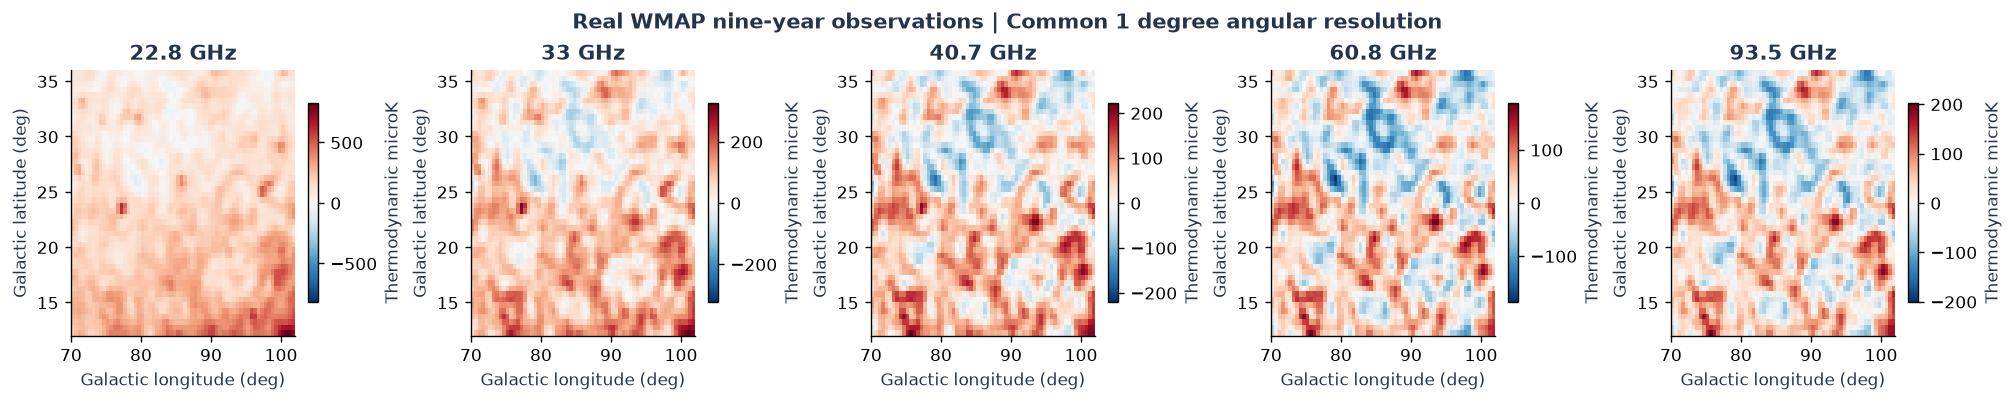

In [2]:
show('acquisition',viz.acquisition(data))

## 3. Forward physics and conditioning

At each sky position p the calibrated five-channel vector is

$$d(p)=A m(p)+e(p),\qquad m=(c,s,t)^\mathsf{T}.$$

Here c is cosmic microwave background temperature, s synchrotron amplitude at22.8GHz, t dust amplitude at93.5GHz, and e contains instrument noise and model discrepancy. A has five frequency rows and three emission columns. For frequency nu in Hz, define

$$x=\frac{h\nu}{kT_{\mathrm{CMB}}},\qquad g(\nu)=\frac{(e^x-1)^2}{e^x x^2}.$$

Planck's constant is h=6.62607015e-34J s, Boltzmann's constant k=1.380649e-23J/K, and Tcmb=2.7255K. The columns are

$$A_{\nu,c}=1,\quad A_{\nu,s}=(\nu/\nu_s)^{-3}\,g(\nu)/g(\nu_s),$$
$$A_{\nu,t}=(\nu/\nu_d)^{1+\beta_d}\frac{\exp(h\nu_d/(kT_d))-1}{\exp(h\nu/(kT_d))-1}\frac{g(\nu)}{g(\nu_d)}.$$

The reference frequencies are nu_s=22.8GHz,nu_d=93.5GHz; beta_d=1.54 and Td=20K. Spectral-response columns are dimensionless. Finite singular values establish identifiability under these fixed assumptions, while the condition number quantifies linear noise amplification. Physical foreground-model errors remain even when the inverse is numerically well conditioned.

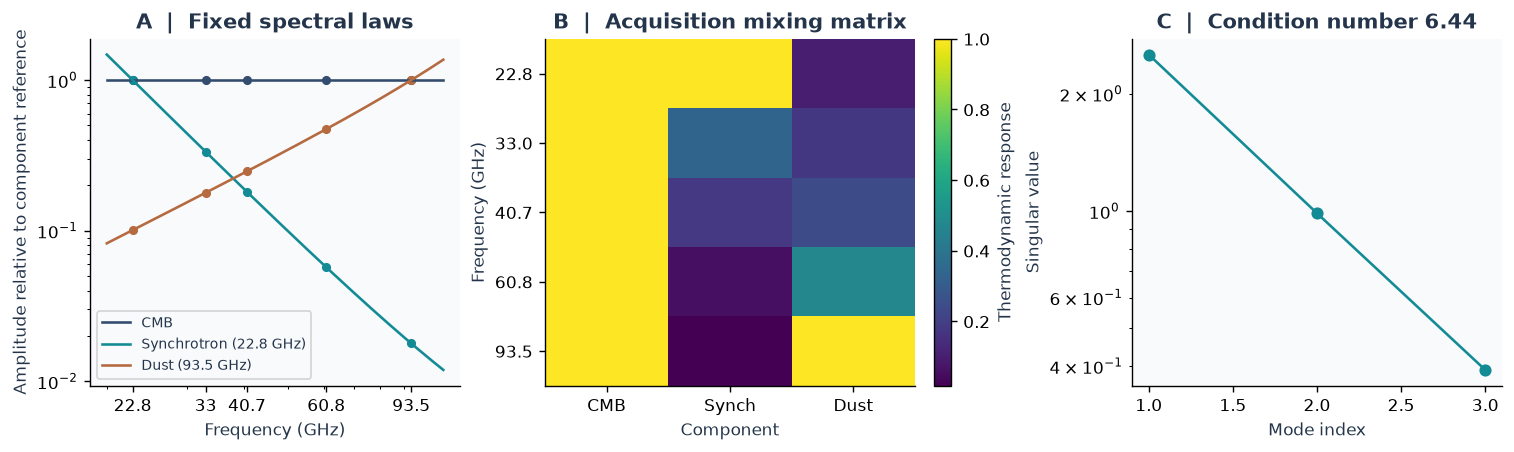

In [3]:
show('spectra',viz.spectra(data))

## 4. Fresh local inverse

The selected fixed-spectrum case minimizes half the sum of squared residuals across the five channels independently at every sky position. Equal channel weights define this reference method; no unmeasured smoothed-pixel covariance is treated as known. The inverse is

$$\hat m=(A^\mathsf{T}A)^{-1}A^\mathsf{T}d=V\operatorname{diag}(1/s)U^\mathsf{T}d,$$

where A=U diag(s)V^T is its reduced singular-value decomposition. The local runtime explicitly computes each physical spectral response and the SVD inverse. No iteration, learned weights, positivity clipping, spatial padding or hidden reference is required. The unit-noise response covariance V diag(1/s²)V^T is a conditioning diagnostic rather than an absolute posterior uncertainty.

The next cell actively reconstructs all3072sky directions and writes all three required output quantities. The author comparison loaded separately was captured by executing the unmodified original FGBuster laws and inverse on these exact observations before implementing the local extraction.

Fresh reconstruction seconds: 0.000258100000792183
{
  "CMB": {
    "ncc": 1.0,
    "dynamic_range_nrmse": 1.814224719175821e-16
  },
  "Synchrotron (22.8 GHz)": {
    "ncc": 0.9999999999999999,
    "dynamic_range_nrmse": 1.2011684556406313e-16
  },
  "Dust (93.5 GHz)": {
    "ncc": 1.0000000000000002,
    "dynamic_range_nrmse": 3.375733231540851e-16
  }
}


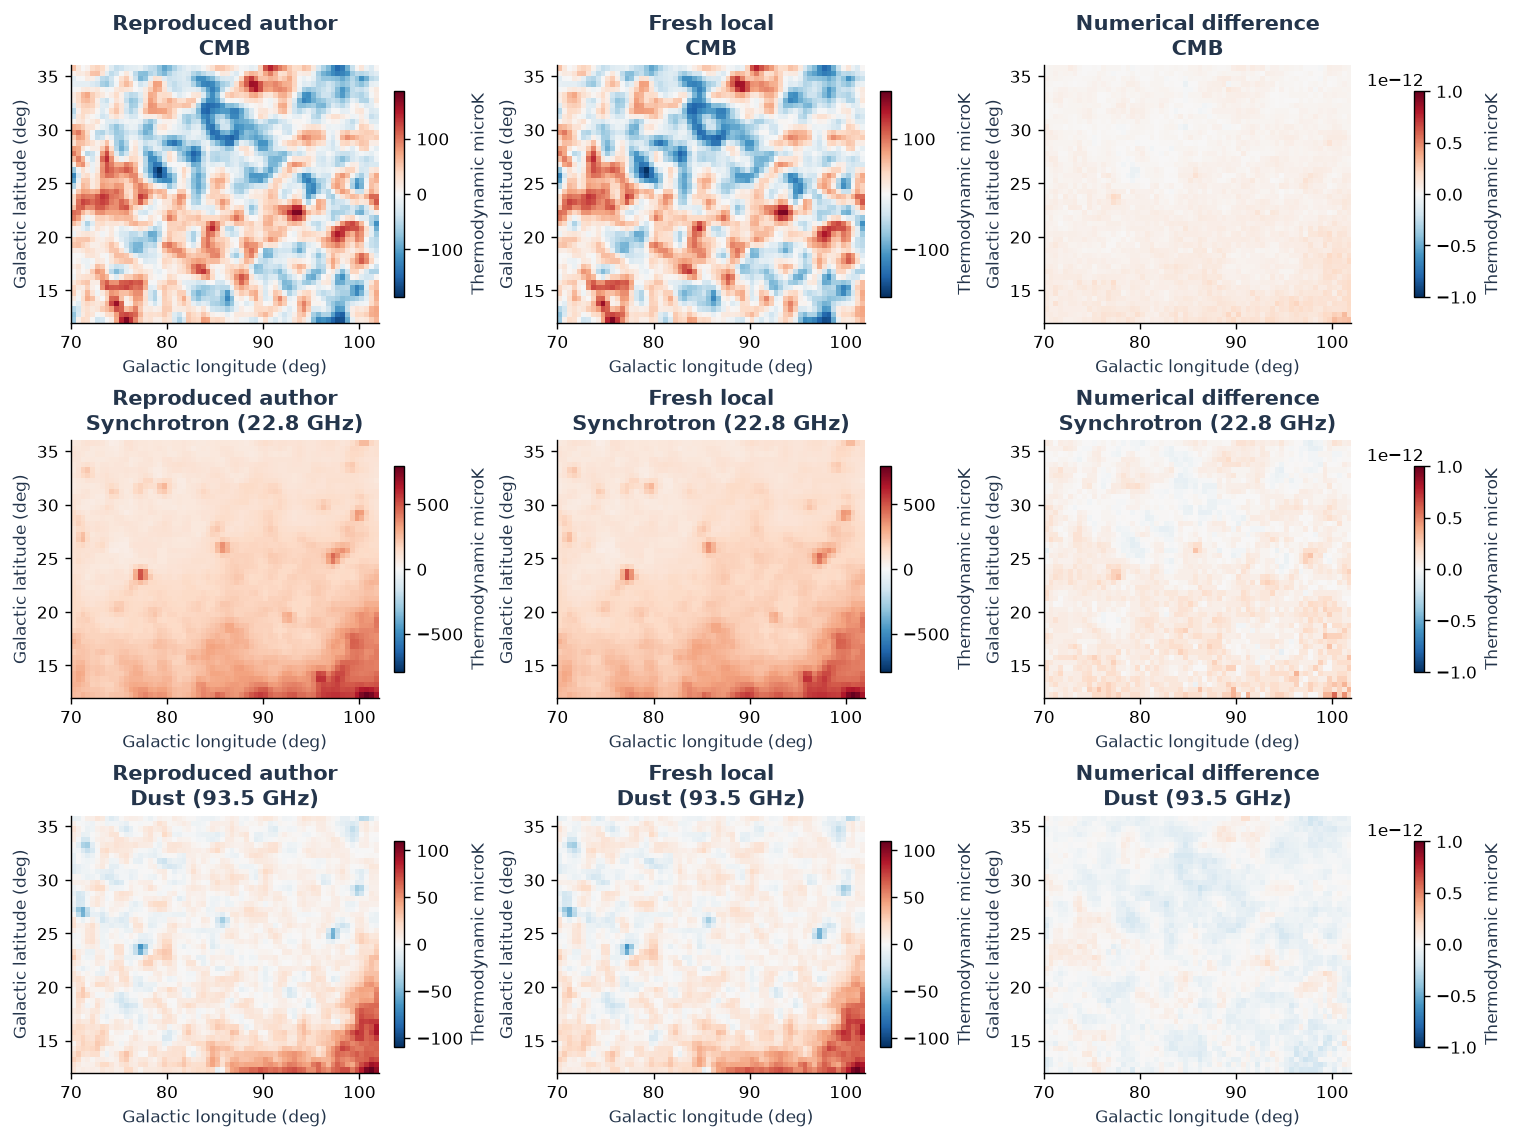

In [4]:
start=time.perf_counter()
fresh,prediction,covariance=reconstruct(data)
runtime=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[0][None],synchrotron=fresh[1][None],dust=fresh[2][None])
metrics={name:{'ncc':viz.compare(fresh[i],author[i])[0],'dynamic_range_nrmse':viz.compare(fresh[i],author[i])[1]} for i,name in enumerate(viz.NAMES)}
print('Fresh reconstruction seconds:',runtime)
print(json.dumps(metrics,indent=2,allow_nan=False))
show('components',viz.components(data,fresh,author))

## 5. Scientific comparisons and model sensitivity

Forward residual maps show what is not described by the three fixed spectra. They include unmodeled foreground behavior, effective-frequency approximations and noise; no independent per-channel covariance is supplied, so a unit-chi-square claim would be unjustified.

The two-component ablation actually solves a separate CMB+synchrotron inverse. Its difference from the three-component CMB map shows foreground leakage caused by dropping dust. The nine-value synchrotron-index sweep and five leave-one-band-out inverses are computed from the same observations. They measure model dependence and frequency leverage rather than validating against unavailable sky truth.

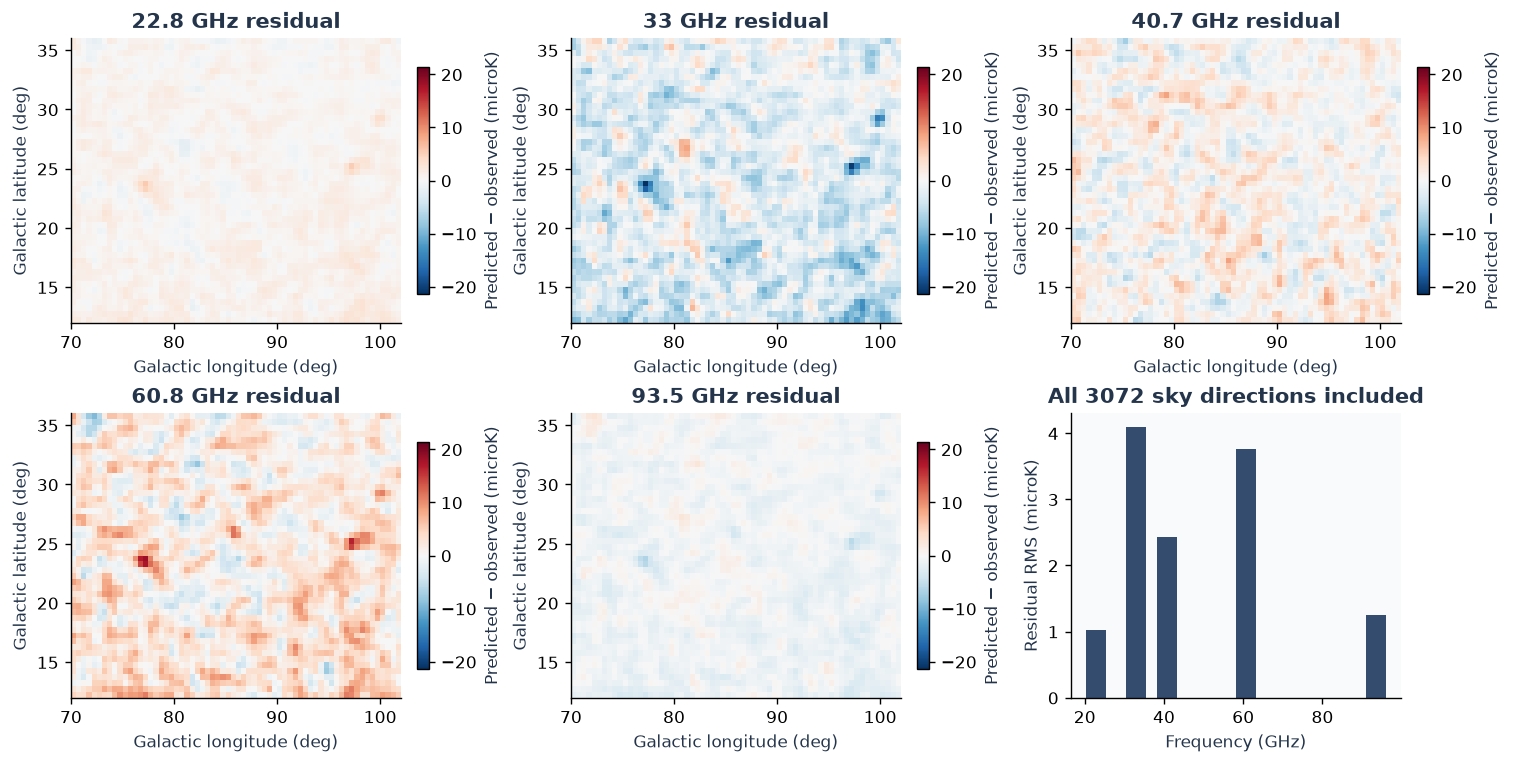

In [5]:
show('residuals',viz.residuals(data,prediction))

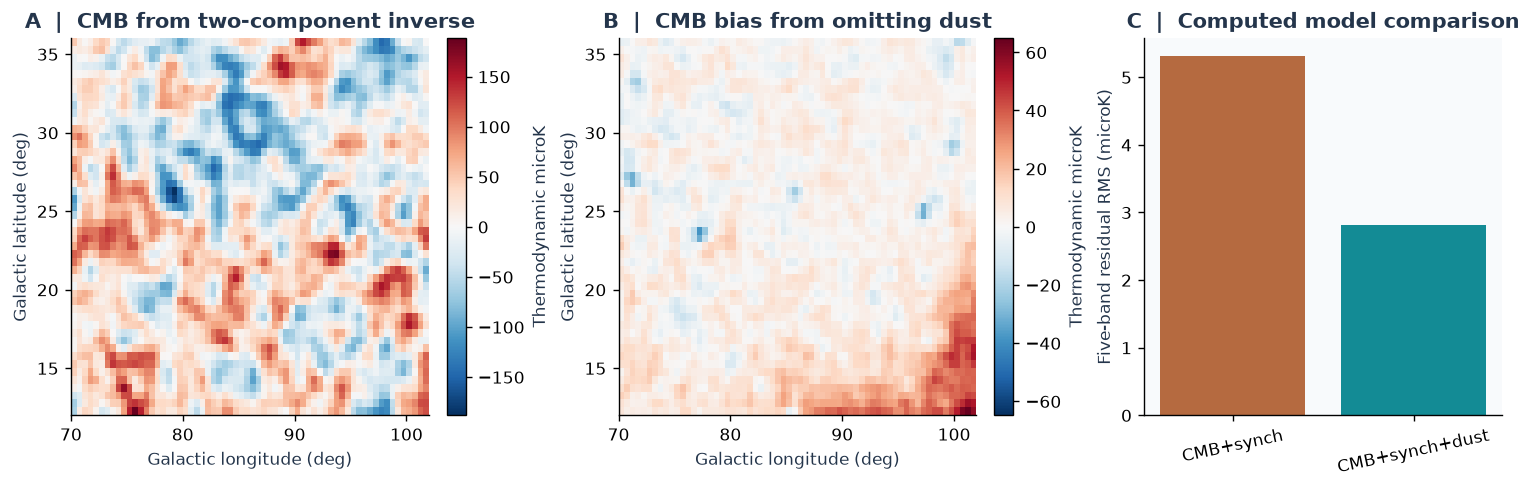

In [6]:
show('ablation',viz.ablation(data,fresh))

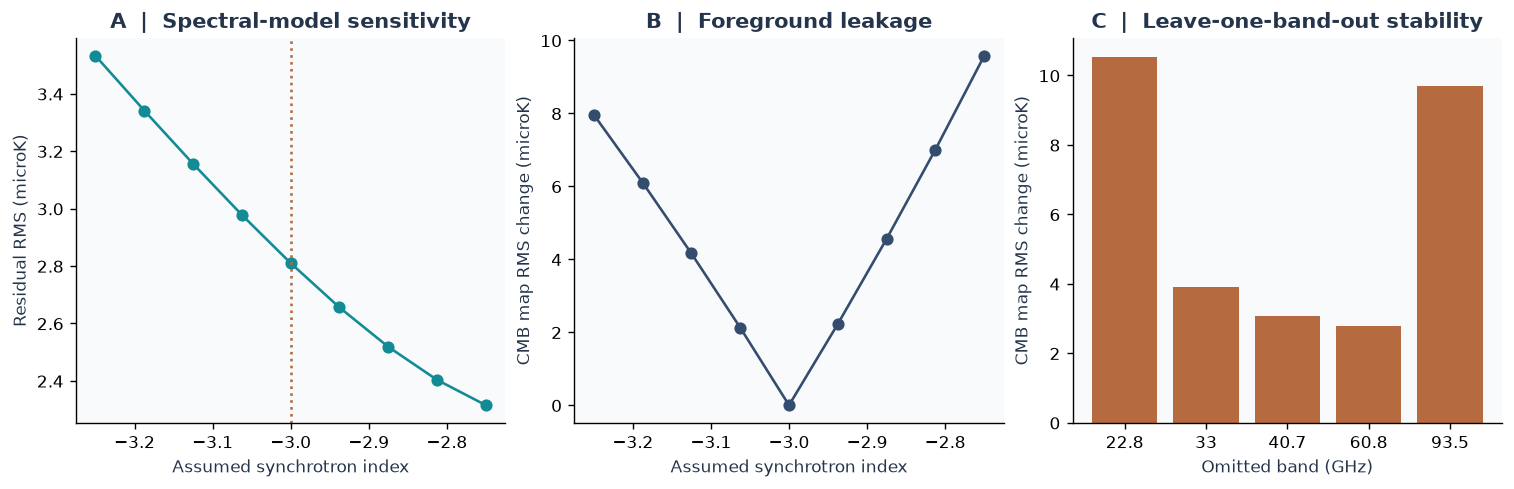

In [7]:
show('sensitivity',viz.sensitivity(data,fresh))

In [8]:
import subprocess
run=subprocess.run([sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')],capture_output=True,text=True)
assert run.returncode==0,(run.stdout,run.stderr)
print((root/'output/judge_report.json').read_text())
print('Five-band residual RMS microK:',float(np.sqrt(np.mean((prediction-data['measurements'])**2))))

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999999,
    "reconstruction_nrmse": 1.8142247191758207e-16,
    "synchrotron_ncc": 1.0000000000000002,
    "synchrotron_nrmse": 1.2011684556406313e-16,
    "dust_ncc": 1.0000000000000002,
    "dust_nrmse": 3.3757332315408513e-16
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "synchrotron_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "synchrotron_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "dust_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "dust_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}
Five-band residual RMS microK: 2.8100211877644186


## 6. Interpretation and limits

The fresh maps reproduce the independent standard-method inverse while preserving physical temperature scale, reference frequencies and all required component outputs. The small numerical parity difference is distinct from the scientifically nonzero observation residual. Negative inferred amplitudes remain visible because a differential sky and imperfect fixed spectra do not justify clipping them to zero.

The ablations show why frequency diversity and foreground modeling matter to the recovered cosmic microwave background map. The result remains conditional on fixed spectra, a monochromatic frequency approximation, common nominal beam resolution and equal channel weighting. It is suitable for benchmarking a reproducible spatial spectral inverse; a cosmological power-spectrum or physical foreground-parameter claim would require additional treatment of bandpasses, masks, calibration, noise covariance and spatially varying emission laws. See `test/validation.md` for exact source/data provenance and executed gates.